In [1]:
%pip install nltk
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas
import numpy
import matplotlib.pyplot
import nltk
import spacy
import Sastrawi
import sklearn

print("Environment NLP siap digunakan.")

Environment NLP siap digunakan.


In [5]:
import sys
print(sys.executable)

c:\Users\Lenovo\Documents\NLP\modul-1\.venv\Scripts\python.exe


In [6]:
import os

print(os.getcwd())

###################
import os

print(os.listdir())

c:\Users\Lenovo\Documents\NLP\modul-1
['.venv', 'linguistic_processing.ipynb', 'test_environment.ipynb', 'text_normalization.ipynb', 'tokenization.ipynb']


In [1]:
#Extract dataset
import pandas as pd

#Membaca dataset
data = pd.read_csv('dataset.csv')

#menampilkan 10 data teratas
print(data.head(10))

#Melihat 10 data terakhir
print(data.tail(10))

  date_publication media_source  \
0       2026-01-01       Kontan   
1       2026-01-01       Kontan   
2       2026-01-01       Kontan   
3       2026-01-01       Kontan   
4       2026-01-01       Kontan   
5       2026-01-01       Kontan   
6       2026-01-01       Kontan   
7       2026-01-01       Kontan   
8       2026-01-01       Kontan   
9       2026-01-01       Kontan   

                                       title_article  \
0  Harga Emas Antam Hari Ini (28/3) Naik Rp 27.00...   
1  Kejagung Tetapkan Samin Tan Tersangka, Ini Kas...   
2  Asing Net Sell Rp 20,38 Triliun, Cek Saham yan...   
3                          Berburu Emas di Pagi Buta   
4  Hampir Rampung, ESDM Restui RKAB Batubara 580 ...   
5  Iran Beri Sinyal Positif, 2 Kapal Tanker Perta...   
6  Yuk Lihat Harga Emas Hari Ini di Pegadaian Sab...   
7  Indocement Tunggal Prakarsa (INTP) Bentuk Usah...   
8  Naik Rp 27.000 Per Gram, Cek Harga Emas Antam ...   
9  Bursa Wall Street Memerah di Akhir Perdagangan...  

In [2]:

import pandas as pd

# Load Dataset
data = pd.read_csv("dataset.csv")

# Melihat nama kolom
print(data.columns)

# Info dataset
data.info()

# Ukuran dataset
print(data.shape)

# Jumlah dokumen
print("Jumlah dokumen:", data.shape[0])

# Memilih kolom teks
text_column = "content_article"
data_teks = data[text_column]

print(data_teks)

# Melihat contoh teks
for text in data_teks.head(5):
    print(text)
    print("-" * 80)


Index(['date_publication', 'media_source', 'title_article', 'content_article',
       'url_article', 'sentiment_label', 'polarity_score', 'ai_confidence'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date_publication  3376 non-null   str    
 1   media_source      3376 non-null   str    
 2   title_article     3376 non-null   str    
 3   content_article   3376 non-null   str    
 4   url_article       3376 non-null   str    
 5   sentiment_label   3376 non-null   str    
 6   polarity_score    3376 non-null   float64
 7   ai_confidence     3376 non-null   float64
dtypes: float64(2), str(6)
memory usage: 211.1 KB
(3376, 8)
Jumlah dokumen: 3376
0       Reporter: Noverius Laoli | Editor: Noverius La...
1       Reporter: kompas.com | Editor: Noverius Laoli ...
2       Reporter: Noverius Laoli | Editor: Noverius La...
3    

In [3]:
#Memeriksa missing values
missing_values = data.isnull().sum()
print("Jumlah missing values per kolom:")
print(missing_values)

#Menghitung missing values dalam kolom teks
missing_text = data_teks.isnull().sum()
print("Jumlah missing values dalam kolom teks:")
print(missing_text)

#Menghapus data kosong
data_cleaned = data.dropna()
print("Data setelah menghapus missing values:")
print(data_cleaned)

#Periksa kembali missing values setelah pembersihan
missing_values_after_cleaning = data_cleaned.isnull().sum()
print("Jumlah missing values setelah pembersihan:")
print(missing_values_after_cleaning)

Jumlah missing values per kolom:
date_publication    0
media_source        0
title_article       0
content_article     0
url_article         0
sentiment_label     0
polarity_score      0
ai_confidence       0
dtype: int64
Jumlah missing values dalam kolom teks:
0
Data setelah menghapus missing values:
     date_publication media_source  \
0          2026-01-01       Kontan   
1          2026-01-01       Kontan   
2          2026-01-01       Kontan   
3          2026-01-01       Kontan   
4          2026-01-01       Kontan   
...               ...          ...   
3371       2026-03-31         CNBC   
3372       2026-03-31         CNBC   
3373       2026-03-31         CNBC   
3374       2026-03-31         CNBC   
3375       2026-03-31   Bisnis.com   

                                          title_article  \
0     Harga Emas Antam Hari Ini (28/3) Naik Rp 27.00...   
1     Kejagung Tetapkan Samin Tan Tersangka, Ini Kas...   
2     Asing Net Sell Rp 20,38 Triliun, Cek Saham yan...   
3   

In [4]:
#Memeriksa duplikasi
duplicates = data.duplicated()
print("Jumlah data duplikat:")
print(duplicates.sum())

#Memeriksa duplikasi dalam kolom teks
duplicates_text = data_teks.duplicated()
print("Jumlah data duplikat dalam kolom teks:")
print(duplicates_text.sum())

#Menghapus duplikasi
data_no_duplicates = data.drop_duplicates()
print("Data setelah menghapus duplikasi:")
print(data_no_duplicates)

Jumlah data duplikat:
0
Jumlah data duplikat dalam kolom teks:
22
Data setelah menghapus duplikasi:
     date_publication media_source  \
0          2026-01-01       Kontan   
1          2026-01-01       Kontan   
2          2026-01-01       Kontan   
3          2026-01-01       Kontan   
4          2026-01-01       Kontan   
...               ...          ...   
3371       2026-03-31         CNBC   
3372       2026-03-31         CNBC   
3373       2026-03-31         CNBC   
3374       2026-03-31         CNBC   
3375       2026-03-31   Bisnis.com   

                                          title_article  \
0     Harga Emas Antam Hari Ini (28/3) Naik Rp 27.00...   
1     Kejagung Tetapkan Samin Tan Tersangka, Ini Kas...   
2     Asing Net Sell Rp 20,38 Triliun, Cek Saham yan...   
3                             Berburu Emas di Pagi Buta   
4     Hampir Rampung, ESDM Restui RKAB Batubara 580 ...   
...                                                 ...   
3371   Video: Perang Iran VS A

In [4]:
#Menghitung jumlah karakter
data['jumlah_karakter'] = data[text_column].str.len()
print("Jumlah karakter per baris:")
print(data['jumlah_karakter'])

#Menghitung jumlah kata
data['jumlah_kata'] = data[text_column].str.split().str.len()
print("Jumlah kata per baris:")
print(data['jumlah_kata'])

#Statistik jumlah kata
print("Statistik jumlah kata:")
print(data['jumlah_kata'].describe())

Jumlah karakter per baris:
0       1528
1       2179
2       1987
3         29
4       1788
        ... 
3371     387
3372    2791
3373    1258
3374    1752
3375    2746
Name: jumlah_karakter, Length: 3376, dtype: int64
Jumlah kata per baris:
0       243
1       262
2       302
3         3
4       250
       ... 
3371     52
3372    390
3373    168
3374    244
3375    387
Name: jumlah_kata, Length: 3376, dtype: int64
Statistik jumlah kata:
count    3376.000000
mean      383.772512
std       175.876288
min         3.000000
25%       268.000000
50%       361.000000
75%       463.000000
max      1438.000000
Name: jumlah_kata, dtype: float64


In [5]:
#Menghitung jumlah kalimat
import nltk
nltk.download('punkt')
nltk.download("punkt_tab")

from nltk.tokenize import sent_tokenize

#contoh
text_example = "Saya belajar NLP. NLP sangat menarik."
sentences = sent_tokenize(text_example)
print(sentences)

#Menghitung jumlah kalimat dalam dataset
data['jumlah_kalimat'] = data[text_column].astype(str).apply(lambda x: len(sent_tokenize(x)))
print("Jumlah kalimat per baris:")
print(data['jumlah_kalimat'])

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


['Saya belajar NLP.', 'NLP sangat menarik.']
Jumlah kalimat per baris:
0       10
1       18
2       25
3        1
4       15
        ..
3371     3
3372    20
3373     8
3374    19
3375    30
Name: jumlah_kalimat, Length: 3376, dtype: int64


In [6]:
#Melihat statistik corpus
print("jumlah_dokumen:", data.shape[0])
print("jumlah kata:", data['jumlah_kata'].sum())
print("jumlah_kalimat:", data['jumlah_kalimat'].sum())
print("jumlah karakter:", data['jumlah_karakter'].sum())

jumlah_dokumen: 3376
jumlah kata: 1295616
jumlah_kalimat: 71448
jumlah karakter: 9429151


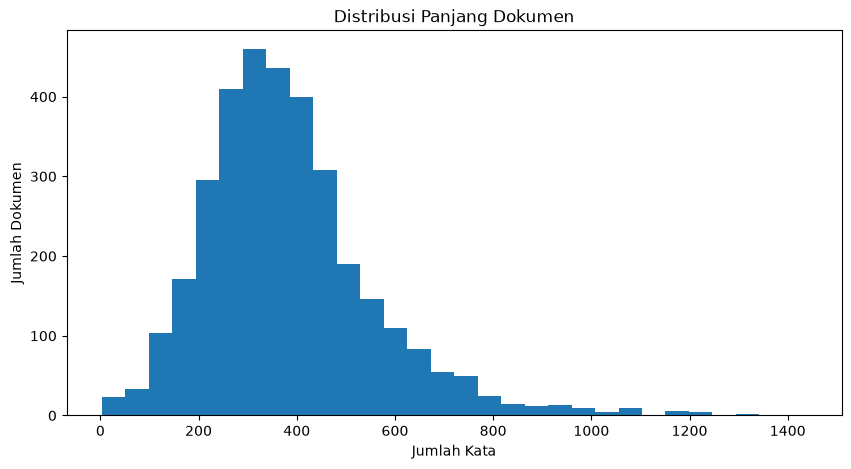

In [9]:

# Visualisasi distribusi panjang dokumen
import matplotlib.pyplot as plt

# Menghitung jumlah kata setiap artikel
data["jumlah_kata"] = data["content_article"].fillna("").apply(
    lambda teks: len(str(teks).split())
)

# Membuat histogram
plt.figure(figsize=(10, 5))
plt.hist(data["jumlah_kata"], bins=30)

plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.show()
